In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import keras_tuner as kt
df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")

2026-05-04 01:02:26.531122: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-04 01:02:26.542108: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-04 01:02:26.582706: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-04 01:02:26.582737: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-04 01:02:26.582770: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [3]:
df.columns

Index(['timestamp', 'symbol', 'open', 'high', 'low', 'close', 'volume',
       'sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20', 'target_up_next', 'day', 'hour',
       'scores_0', 'scores_1', 'scores_2', 'scores_3', 'scores_4', 'scores_5',
       'scores_6', 'scores_7', 'scores_8', 'scores_9', 'scores_10',
       'scores_11', 'scores_12', 'scores_13', 'scores_14', 'scores_15',
       'scores_16', 'scores_17', 'scores_18', 'scores_19', 'scores_20',
       'scores_21', 'scores_22', 'sum_of_scores', 'avg_of_scores',
       'normalized_avg', 'max_of_scores', 'min_of_scores', 'normalized_min',
       'normalized_max', 'avg_score_of_normalized_min',
       'avg_score_of_normalized_max', 'avg_score_of_normalized_avg'],
      dtype='object')

In [4]:
df["sum_of_scores"]

0               [-7, 2, 7, 1, -2, 5, 2, 0, 1, 5]
1              [2, 5, 0, 3, -1, 4, 0, -2, -2, 4]
2       [-18, 14, 10, 10, 2, 11, -2, 15, -7, -7]
3            [-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]
4           [-20, 2, 19, 16, 6, 16, 4, 5, -2, 9]
                          ...                   
1032              [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
1033              [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
1034              [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
1035              [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
1036              [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Name: sum_of_scores, Length: 1037, dtype: object

In [5]:
df["normalized_avg"]

0       [-0.7, 0.2, 0.7, 0.1, -0.2, 0.5, 0.2, 0.0, 0.1...
1       [0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....
2       [-0.6, 0.4666666666666667, 0.33333333333333337...
3       [-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...
4       [-0.5, 0.05, 0.475, 0.4, 0.15, 0.4, 0.1, 0.125...
                              ...                        
1032    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
1033    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
1034    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
1035    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
1036    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
Name: normalized_avg, Length: 1037, dtype: object

Raw data: 1037 rows, 51 cols
Features (13): ['return', 'avg_score_of_normalized_min', 'avg_score_of_normalized_max', 'avg_score_of_normalized_avg', 'avg_score_of_normalized_min_lag1', 'avg_score_of_normalized_max_lag1', 'avg_score_of_normalized_avg_lag1', 'avg_score_of_normalized_min_lag2', 'avg_score_of_normalized_max_lag2', 'avg_score_of_normalized_avg_lag2', 'avg_score_of_normalized_min_lag3', 'avg_score_of_normalized_max_lag3', 'avg_score_of_normalized_avg_lag3']
Labels: up=523 (50.5%) down=513 (49.5%)
Windows: (1016, 20, 13), labels: (1016,)

NAIVE BASELINES

=== Always-Up (mean +/- std across 5 folds) ===
  Accuracy     :  0.5053 +/- 0.0325
  BalancedAcc  :  0.5000 +/- 0.0000
  F1           :  0.6708 +/- 0.0286
  MCC          :  0.0000 +/- 0.0000
  Brier        :  0.4947 +/- 0.0325
  ROC-AUC      :  0.5000 +/- 0.0000

=== Majority-Class (mean +/- std across 5 folds) ===
  Accuracy     :  0.4876 +/- 0.0305
  BalancedAcc  :  0.5000 +/- 0.0000
  F1           :  0.5298 +/- 0.2659
  M

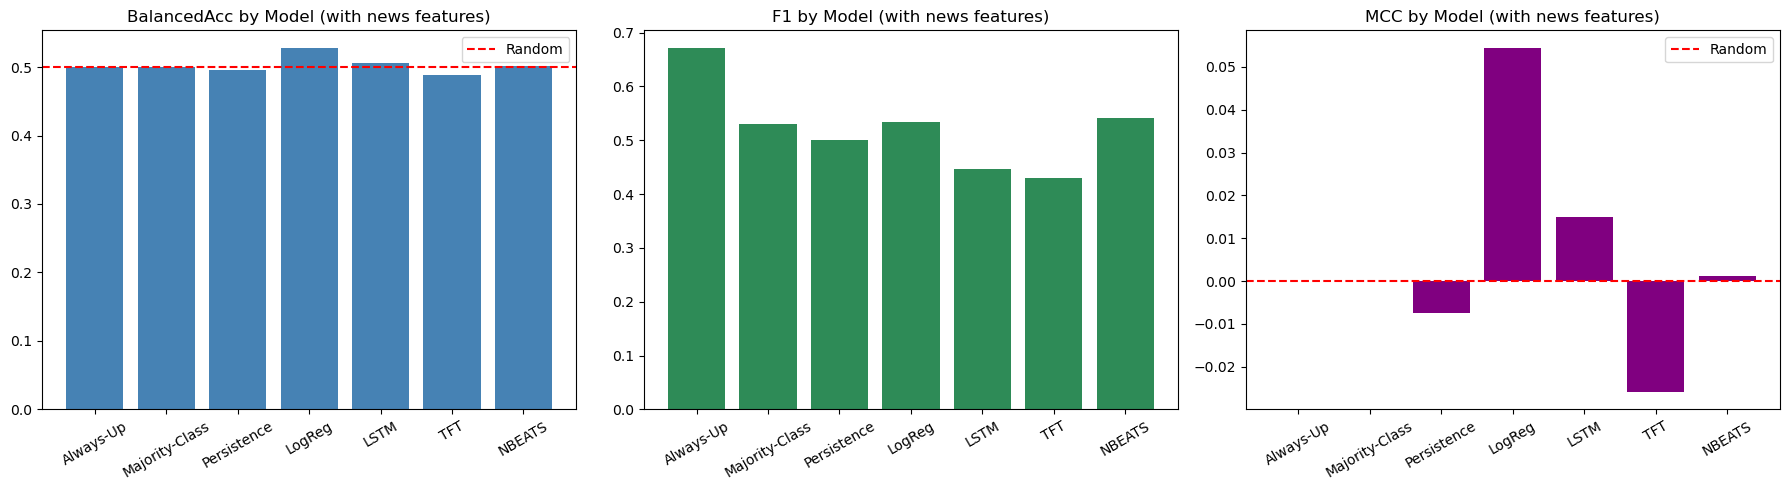

Saved -> classification_with_news_comparison.png


In [9]:
"""
================================================================================
Tesla Direction Classification with NEWS SENTIMENT features (multivariate)
================================================================================
Adds news-sentiment features to the binary up/down classifier.

Feature engineering principles applied:
  - Drop sparse raw scores_0..scores_22 (mostly noise, inconsistent across rows)
  - Use aggregate metrics + missing-data signal (score_count)
  - Add lagged sentiment (sentiment effects are delayed 1-3 days)
  - Add a "no news" flag
  - Robust handling of NaNs (forward-fill cautiously, then zero-fill)

Models: same as before -- naive baselines, LogReg, LSTM, TFT, N-BEATS.
================================================================================
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, LSTM, Dropout, LayerNormalization,
    MultiHeadAttention, GlobalAveragePooling1D, Add, Subtract, Flatten
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
    roc_auc_score, brier_score_loss
)
import keras_tuner as kt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================================
# 1. CONFIG
# ============================================================================
CSV_PATH    = "brian_news_stocks_tesla_2023_processses_with_agg.csv"
TARGET_COL  = "close"
TIME_COL    = "timestamp"
LOOKBACK    = 20
N_SPLITS    = 5
MAX_TRIALS  = 10
TUNE_EPOCHS = 25
FIT_EPOCHS  = 100
BATCH_SIZE  = 32

# ============================================================================
# 2. FEATURE ENGINEERING
# ============================================================================
def build_features(df, lags=(1, 2, 3)):
    """
    Build features from close price + 3 precomputed score columns.
    """
    df = df.sort_values(TIME_COL).reset_index(drop=True).copy()

    # ---- Price feature (return = stationary input) ----
    df["return"] = df[TARGET_COL].pct_change().fillna(0)

    # ---- Score features (use precomputed columns directly) ----
    score_features = [
        "avg_score_of_normalized_min",
        "avg_score_of_normalized_max",
        "avg_score_of_normalized_avg",
    ]
    # Coerce to numeric and fill NaNs with 0 (neutral)
    for c in score_features:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0)

    # ---- Lagged score features (sentiment effects often delayed 1-3 days) ----
    for lag in lags:
        for c in score_features:
            df[f"{c}_lag{lag}"] = df[c].shift(lag).fillna(0)

    # ---- Final feature set ----
    feature_cols = ["return"] + score_features + [
        f"{c}_lag{lag}" for lag in lags for c in score_features
    ]

    # ---- Shift features by 1: at time t we only know features through t-1 ----
    for c in feature_cols:
        df[c] = df[c].shift(1)

    # ---- Target: did price go up from t-1 to t? ----
    # Window ending at row t-1 (with shifted features) predicts close[t] vs close[t-1]
    df["target"] = (df[TARGET_COL] > df[TARGET_COL].shift(1)).astype(int)

    # Drop first row (NaN from shift) and any other NaNs
    df = df.dropna(subset=feature_cols + ["target"]).reset_index(drop=True)

    feats = df[feature_cols]
    target = df["target"].values.astype(int)
    return feats, target, feature_cols


def create_multivariate_windows(features_df, target, look_back=LOOKBACK):
    """Build (samples, look_back, n_features) windows from a DataFrame of features."""
    arr = features_df.values.astype("float32")
    X, y = [], []
    for i in range(len(arr) - look_back):
        X.append(arr[i : i + look_back])
        y.append(target[i + look_back - 1])  # target aligned with last bar in window
    return np.array(X), np.array(y, dtype="int32")


# ============================================================================
# 3. METRICS UTILITIES
# ============================================================================
def classification_metrics(y_true, y_pred_proba, threshold=0.5):
    y_true = np.asarray(y_true).flatten()
    y_proba = np.asarray(y_pred_proba).flatten()
    y_pred = (y_proba >= threshold).astype(int)
    metrics = {
        "Accuracy":     accuracy_score(y_true, y_pred),
        "BalancedAcc":  balanced_accuracy_score(y_true, y_pred),
        "F1":           f1_score(y_true, y_pred, zero_division=0),
        "MCC":          matthews_corrcoef(y_true, y_pred),
        "Brier":        brier_score_loss(y_true, y_proba),
    }
    metrics["ROC-AUC"] = (roc_auc_score(y_true, y_proba)
                         if len(np.unique(y_true)) > 1 else np.nan)
    return metrics


def find_best_threshold(y_true, y_proba):
    best_t, best_score = 0.5, -1
    for t in np.linspace(0.3, 0.7, 41):
        score = balanced_accuracy_score(y_true, (y_proba >= t).astype(int))
        if score > best_score:
            best_score, best_t = score, t
    return best_t


def summarize(metrics_list, name=""):
    print(f"\n=== {name} (mean +/- std across {len(metrics_list)} folds) ===")
    for k in metrics_list[0].keys():
        vals = [m[k] for m in metrics_list if not np.isnan(m[k])]
        if vals:
            print(f"  {k:13s}: {np.mean(vals):7.4f} +/- {np.std(vals):.4f}")


# ============================================================================
# 4. LOAD + FEATURE BUILD
# ============================================================================
df_raw = pd.read_csv(CSV_PATH)
print(f"Raw data: {len(df_raw)} rows, {df_raw.shape[1]} cols")

feats_df, y_all, feature_cols = build_features(df_raw)
print(f"Features ({len(feature_cols)}): {feature_cols}")
print(f"Labels: up={y_all.sum()} ({y_all.mean()*100:.1f}%) "
      f"down={(1-y_all).sum()} ({(1-y_all.mean())*100:.1f}%)")

X_all, y_seq = create_multivariate_windows(feats_df, y_all, LOOKBACK)
N_FEATURES = X_all.shape[-1]
print(f"Windows: {X_all.shape}, labels: {y_seq.shape}")


# ============================================================================
# 5. SCALING HELPER (per-fold, fit on train only)
# ============================================================================
def scale_windows(X_train, X_test):
    """Fit per-feature StandardScaler on train, apply to both."""
    n, lb, f = X_train.shape
    sc = StandardScaler().fit(X_train.reshape(-1, f))
    X_tr = sc.transform(X_train.reshape(-1, f)).reshape(n, lb, f)
    X_te = sc.transform(X_test.reshape(-1, f)).reshape(X_test.shape)
    return X_tr, X_te


# ============================================================================
# 6. NAIVE BASELINES
# ============================================================================
def evaluate_naive_baselines(X, y):
    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    results = {"Always-Up": [], "Majority-Class": [], "Persistence": []}
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X), 1):
        y_tr, y_te = y[tr_idx], y[te_idx]
        X_te = X[te_idx]
        results["Always-Up"].append(
            classification_metrics(y_te, np.ones(len(y_te))))
        maj = int(y_tr.mean() >= 0.5)
        results["Majority-Class"].append(
            classification_metrics(y_te, np.full(len(y_te), maj)))
        # Persistence: predict same direction as last bar's return (feature 0)
        last_return = X_te[:, -1, 0]
        results["Persistence"].append(
            classification_metrics(y_te, (last_return > 0).astype(int)))
    return results


# ============================================================================
# 7. LOGISTIC REGRESSION (sanity-check baseline on flattened features)
# ============================================================================
def run_logreg(X, y):
    """Flatten the time window into one big vector and run LogReg."""
    print("\n>>> Logistic Regression on flattened features")
    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X), 1):
        X_tr_w, X_te_w = X[tr_idx], X[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]

        # Flatten (samples, lookback, features) -> (samples, lookback*features)
        X_tr = X_tr_w.reshape(len(X_tr_w), -1)
        X_te = X_te_w.reshape(len(X_te_w), -1)
        sc = StandardScaler().fit(X_tr)
        X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)

        clf = LogisticRegression(class_weight="balanced", max_iter=2000, C=0.5)
        clf.fit(X_tr, y_tr)
        proba = clf.predict_proba(X_te)[:, 1]
        m = classification_metrics(y_te, proba)
        fold_metrics.append(m)
        print(f"  LogReg fold {fold}: BalAcc={m['BalancedAcc']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f}")
    return fold_metrics


# ============================================================================
# 8. TUNER WRAPPER
# ============================================================================
def tune_classifier(builder, X_train, y_train, project_name, class_weight=None):
    val_split = int(len(X_train) * 0.8)
    X_tr, X_va = X_train[:val_split], X_train[val_split:]
    y_tr, y_va = y_train[:val_split], y_train[val_split:]
    tuner = kt.BayesianOptimization(
        builder,
        objective=kt.Objective("val_auc", direction="max"),
        max_trials=MAX_TRIALS,
        directory="kt_dir_mv",
        project_name=project_name,
        overwrite=True, seed=SEED,
    )
    es = EarlyStopping(monitor="val_auc", mode="max", patience=8,
                       min_delta=1e-4, restore_best_weights=True)
    tuner.search(X_tr, y_tr, epochs=TUNE_EPOCHS,
                 validation_data=(X_va, y_va),
                 class_weight=class_weight,
                 callbacks=[es], verbose=0)
    return tuner.get_best_hyperparameters(1)[0]


# ============================================================================
# 9. LSTM CLASSIFIER (multivariate)
# ============================================================================
def build_lstm_classifier(hp, look_back=LOOKBACK, n_features=N_FEATURES):
    model = Sequential()
    n_layers = hp.Int("num_layers", 1, 2)
    for i in range(n_layers):
        units = hp.Int(f"units_{i}", 16, 64, step=16)
        dropout = hp.Float(f"dropout_{i}", 0.1, 0.5, step=0.1)
        return_sequences = (i < n_layers - 1)
        if i == 0:
            model.add(LSTM(units, return_sequences=return_sequences,
                           input_shape=(look_back, n_features)))
        else:
            model.add(LSTM(units, return_sequences=return_sequences))
        model.add(Dropout(dropout))
    model.add(Dense(1, activation="sigmoid"))
    lr = hp.Choice("lr", [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model


# ============================================================================
# 10. TFT CLASSIFIER (multivariate)
# ============================================================================
def gated_residual_network(x, units, dropout=0.1):
    h = Dense(units, activation="elu")(x)
    h = Dense(units)(h)
    h = Dropout(dropout)(h)
    gate = Dense(units, activation="sigmoid")(x)
    if x.shape[-1] != units:
        x = Dense(units)(x)
    return LayerNormalization()(Add()([x, h * gate]))


def build_tft_classifier(hp, look_back=LOOKBACK, n_features=N_FEATURES):
    units    = hp.Int("units", 16, 64, step=16)
    n_heads  = hp.Choice("n_heads", [2, 4])
    dropout  = hp.Float("dropout", 0.1, 0.4, step=0.1)
    lr       = hp.Choice("lr", [1e-3, 5e-4, 1e-4])

    inp = Input(shape=(look_back, n_features))
    enc = LSTM(units, return_sequences=True)(inp)
    enc = gated_residual_network(enc, units, dropout)
    attn = MultiHeadAttention(num_heads=n_heads, key_dim=units)(enc, enc)
    attn = Dropout(dropout)(attn)
    x = LayerNormalization()(Add()([enc, attn]))
    x = gated_residual_network(x, units, dropout)
    x = GlobalAveragePooling1D()(x)
    out = Dense(1, activation="sigmoid")(x)
    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model


# ============================================================================
# 11. N-BEATS CLASSIFIER (multivariate -> flatten then MLP blocks)
# ============================================================================
def nbeats_block(x, units, flat_size):
    h = x
    for _ in range(4):
        h = Dense(units, activation="relu")(h)
    backcast = Dense(flat_size, activation="linear")(h)
    forecast = Dense(units, activation="linear")(h)
    return backcast, forecast


def build_nbeats_classifier(hp, look_back=LOOKBACK, n_features=N_FEATURES):
    units    = hp.Int("units", 32, 128, step=32)
    n_blocks = hp.Int("n_blocks", 2, 4)
    dropout  = hp.Float("dropout", 0.1, 0.4, step=0.1)
    lr       = hp.Choice("lr", [1e-3, 5e-4, 1e-4])
    flat_size = look_back * n_features

    inp = Input(shape=(look_back, n_features))
    flat = Flatten()(inp)
    residual = flat
    forecast_sum = None
    for _ in range(n_blocks):
        backcast, fc = nbeats_block(residual, units, flat_size)
        residual = Subtract()([residual, backcast])
        forecast_sum = fc if forecast_sum is None else Add()([forecast_sum, fc])
    x = Dropout(dropout)(forecast_sum)
    out = Dense(1, activation="sigmoid")(x)
    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model


# ============================================================================
# 12. WALK-FORWARD RUNNER (shared)
# ============================================================================
def run_dl_classifier(X, y, builder, project_name, name):
    print(f"\n>>> {name} Classifier")
    split = int(len(X) * 0.7)

    cw_arr = compute_class_weight("balanced",
                                  classes=np.unique(y[:split]), y=y[:split])
    cw = {i: w for i, w in enumerate(cw_arr)}
    # Need scaled X for tuning too -> use a temporary scaler on tune slice
    X_tune_tr, X_tune_te = scale_windows(X[:split], X[:split])
    best_hp = tune_classifier(builder, X_tune_tr, y[:split],
                              project_name, class_weight=cw)
    print(f"  Best HPs: {best_hp.values}")

    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X), 1):
        X_tr_raw, X_te_raw = X[tr_idx], X[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]
        X_tr, X_te = scale_windows(X_tr_raw, X_te_raw)

        val_split = int(len(X_tr) * 0.85)
        X_t, X_v = X_tr[:val_split], X_tr[val_split:]
        y_t, y_v = y_tr[:val_split], y_tr[val_split:]
        cw_arr = compute_class_weight("balanced",
                                      classes=np.unique(y_t), y=y_t)
        cw = {i: w for i, w in enumerate(cw_arr)}

        model = builder(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_auc", mode="max", patience=15,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=6, factor=0.5),
        ]
        model.fit(X_t, y_t, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_v, y_v),
                  class_weight=cw, callbacks=callbacks, verbose=0)

        val_proba = model.predict(X_v, verbose=0).flatten()
        best_t = find_best_threshold(y_v, val_proba)
        test_proba = model.predict(X_te, verbose=0).flatten()
        m = classification_metrics(y_te, test_proba, threshold=best_t)
        m["Threshold"] = best_t
        fold_metrics.append(m)
        print(f"  {name} fold {fold}: BalAcc={m['BalancedAcc']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f} thr={best_t:.2f}")
    return fold_metrics


# ============================================================================
# 13. FEATURE IMPORTANCE (LogReg coefficients)
# ============================================================================
def show_feature_importance(X, y, feature_cols, look_back=LOOKBACK):
    """Train LogReg on full dataset, report coefficient magnitudes per feature."""
    X_flat = X.reshape(len(X), -1)
    sc = StandardScaler().fit(X_flat)
    X_flat = sc.transform(X_flat)
    clf = LogisticRegression(class_weight="balanced", max_iter=2000, C=0.5)
    clf.fit(X_flat, y)
    coefs = clf.coef_.flatten()  # shape: (look_back * n_features,)
    coefs = coefs.reshape(look_back, len(feature_cols))
    avg_abs_coef = np.abs(coefs).mean(axis=0)  # average importance per feature
    importance = pd.DataFrame({
        "feature": feature_cols,
        "avg_abs_coef": avg_abs_coef
    }).sort_values("avg_abs_coef", ascending=False)
    print("\n=== Feature Importance (LogReg, mean |coef| over time) ===")
    print(importance.to_string(index=False))
    return importance


# ============================================================================
# 14. MAIN
# ============================================================================
if __name__ == "__main__":
    results = {}

    print("\n" + "="*70)
    print("NAIVE BASELINES")
    print("="*70)
    naive = evaluate_naive_baselines(X_all, y_seq)
    for name, folds in naive.items():
        results[name] = folds
        summarize(folds, name)

    print("\n" + "="*70)
    print("LOGISTIC REGRESSION")
    print("="*70)
    results["LogReg"] = run_logreg(X_all, y_seq)
    summarize(results["LogReg"], "LogReg")

    # Feature importance check (run once on full data, just for inspection)
    show_feature_importance(X_all, y_seq, feature_cols)

    print("\n" + "="*70)
    print("LSTM CLASSIFIER (multivariate)")
    print("="*70)
    results["LSTM"] = run_dl_classifier(X_all, y_seq, build_lstm_classifier,
                                        "lstm_mv", "LSTM")
    summarize(results["LSTM"], "LSTM")

    print("\n" + "="*70)
    print("TFT CLASSIFIER (multivariate)")
    print("="*70)
    results["TFT"] = run_dl_classifier(X_all, y_seq, build_tft_classifier,
                                       "tft_mv", "TFT")
    summarize(results["TFT"], "TFT")

    print("\n" + "="*70)
    print("N-BEATS CLASSIFIER (multivariate)")
    print("="*70)
    results["NBEATS"] = run_dl_classifier(X_all, y_seq, build_nbeats_classifier,
                                          "nbeats_mv", "NBEATS")
    summarize(results["NBEATS"], "NBEATS")

    # ---------------------------------------------------------------
    # Comparison table
    # ---------------------------------------------------------------
    print("\n" + "="*70)
    print("FINAL COMPARISON (mean across folds)")
    print("="*70)
    metric_keys = ["Accuracy", "BalancedAcc", "F1", "MCC", "ROC-AUC", "Brier"]
    rows = []
    for name, folds in results.items():
        avg = {k: np.nanmean([f.get(k, np.nan) for f in folds])
               for k in metric_keys}
        rows.append({"Model": name, **avg})
    df_out = pd.DataFrame(rows).round(4)
    print(df_out.to_string(index=False))
    df_out.to_csv("classification_with_news_comparison.csv", index=False)
    print("\nSaved -> classification_with_news_comparison.csv")

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, metric, color in zip(
        axes, ["BalancedAcc", "F1", "MCC"], ["steelblue", "seagreen", "purple"]
    ):
        ax.bar(df_out["Model"], df_out[metric], color=color)
        ax.set_title(f"{metric} by Model (with news features)")
        ax.tick_params(axis="x", rotation=30)
        if metric == "BalancedAcc":
            ax.axhline(0.5, color="red", linestyle="--", label="Random")
            ax.legend()
        elif metric == "MCC":
            ax.axhline(0, color="red", linestyle="--", label="Random")
            ax.legend()
    plt.tight_layout()
    plt.savefig("classification_with_news_comparison.png", dpi=120)
    plt.show()
    print("Saved -> classification_with_news_comparison.png")